# Grammy 2027: Stage 1 with sequential Bayesian updating and forgetting

Team: Yegor Lazarev, Alexander Shayko, Diana Shilova.

This notebook is an **extension of Stage 1** (`grammy_stage1_nomination_probit.ipynb`). It keeps the same target (an artist is nominated
in a category in a season), the same 27 predictors, the same priors and the same eight per-category probit models, and changes only **how
past seasons are combined**.

**Sequential updating.** Instead of refitting on all past seasons, the model is updated one season at a time: the posterior after season
$t-1$ becomes the prior for season $t$, and only season $t$'s data enter the update. Pardoe and Simonton (2008, *JRSS A* 171(2)) tried this for
the Oscars, approximating each posterior by a Normal distribution; it gave the same accuracy as refitting on all data, as Bayes' theorem
implies when nothing is discarded.

**Forgetting.** Before each new season the posterior covariance is inflated by a factor $\lambda \ge 1$:
$$
\text{prior}_t = N\!\left(m_{t-1},\ \lambda\, S_{t-1}\right).
$$
With $\lambda = 1$ nothing is forgotten and the result equals a fit on all past seasons. With $\lambda > 1$ older seasons count less: the
information from a season $k$ years ago is down-weighted roughly by $\lambda^{-k}$. If the Recording Academy's preferences drift (new voting
members since 2019, the end of nomination review committees in 2021), forgetting should help; if they are stable, it should hurt because
each update rests on fewer effective observations.

**Question.** Does forgetting improve one-season-ahead nomination forecasts? We compare $\lambda \in \{1, 1.1, 1.25, 1.5, 2\}$, choose $\lambda$ on
seasons 2012–2023 and report seasons 2024–2025, the same held-out seasons as the main Stage 1 report.

## 1. Data and predictors

The input is the audited `grammy_nomination_dataset.csv` (artist × season × category) used by the main Stage 1 report; its SHA-256 is checked.
The predictor construction below is copied unchanged from the main report (12 chart and Grammy-history predictors, 15 aggregated
other-award predictors with the same category mapping), so any difference in results comes from the updating scheme alone.

In [1]:
import hashlib, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import ndtr, ndtri, log_ndtr
from scipy.linalg import cho_factor, cho_solve
try:
    from IPython.display import display
except ImportError:
    display = print

BASE = Path(".")
DATA_PATH = next(p for p in [BASE / "grammy_nomination_dataset.csv", BASE / "data/grammy_nomination_dataset.csv"] if p.is_file())
EXPECTED_SHA256 = "f2f8a3af293485500c7a792ed333bffaf7671aa075ef49f4f193633bb9d6b62c"
with open(DATA_PATH, "rb") as f:
    assert hashlib.file_digest(f, "sha256").hexdigest() == EXPECTED_SHA256, "input differs from the audited Stage 1 dataset"
data = pd.read_csv(DATA_PATH)
OUTPUT = BASE / "exports_stage1_forgetting"; OUTPUT.mkdir(exist_ok=True)

CATEGORIES = ["album_of_the_year", "record_of_the_year", "song_of_the_year", "best_new_artist",
              "pop_vocal_album", "pop_solo", "pop_duo_group", "music_video"]
FORECAST_SEASON = 2026
FIRST_EVAL, TUNE_END, TEST_SEASONS = 2012, 2023, [2024, 2025]
SCALING_SEASONS_END = 2009          # predictors are standardized once, on seasons 2000-2009
LAMBDAS = [1.0, 1.1, 1.25, 1.5, 2.0]
TOP_K = 5
ALPHA_LOCATION, ALPHA_SCALE, BETA_SCALE = float(ndtri(0.01)), 1.0, 1.0   # same priors as the main report
print(DATA_PATH, data.shape)

grammy_nomination_dataset.csv (203944, 95)


In [2]:
# --- copied from grammy_stage1_nomination_probit.ipynb (category mapping of other awards) ---
RELEVANT_AWARD_STEMS = {
    "ama": {
        "album_of_the_year": ["album_of_the_year", "pop_album"],
        "record_of_the_year": ["song_of_the_year", "pop_song", "collaboration_of_the_year"],
        "song_of_the_year": ["song_of_the_year", "pop_song", "collaboration_of_the_year"],
        "best_new_artist": ["new_artist_of_the_year"],
        "pop_vocal_album": ["pop_album", "album_of_the_year"],
        "pop_solo": ["pop_song", "pop_male_artist", "pop_female_artist"],
        "pop_duo_group": ["pop_duo_group", "collaboration_of_the_year"],
        "music_video": ["music_video"],
    },
    "vma": {
        "album_of_the_year": [],
        "record_of_the_year": ["song_of_the_year", "best_pop", "best_collaboration"],
        "song_of_the_year": ["song_of_the_year", "best_pop", "best_collaboration"],
        "best_new_artist": ["best_new_artist"],
        "pop_vocal_album": ["best_pop"],
        "pop_solo": ["best_pop", "best_male_video", "best_female_video"],
        "pop_duo_group": ["best_group", "best_collaboration"],
        "music_video": ["video_of_the_year"],
    },
    "iheart": {
        "album_of_the_year": [],
        "record_of_the_year": ["song_of_the_year", "pop_song_of_the_year", "best_collaboration"],
        "song_of_the_year": ["song_of_the_year", "pop_song_of_the_year", "best_collaboration"],
        "best_new_artist": ["best_new_artist", "best_new_pop_artist"],
        "pop_vocal_album": ["pop_artist_of_the_year"],
        "pop_solo": ["pop_song_of_the_year", "pop_artist_of_the_year", "male_artist_of_the_year", "female_artist_of_the_year"],
        "pop_duo_group": ["duo_group_of_the_year", "best_collaboration"],
        "music_video": ["best_music_video"],
    },
}

In [3]:
# --- copied from grammy_stage1_nomination_probit.ipynb (award columns and the 27 predictors) ---
AWARD_TOTAL_COLUMNS = ["ama_noms_total", "ama_wins_prev_total",
                       "vma_noms_total", "vma_wins_total",
                       "iheart_noms_total", "iheart_wins_total"]
AWARD_HELD_COLUMNS = ["ama_held", "vma_held", "iheart_held"]
AWARD_FLAG_SUFFIXES = ("_ama_nominated", "_ama_winner_prev",
                       "_vma_nominated", "_vma_winner",
                       "_iheart_nominated", "_iheart_winner")
AWARD_FLAG_COLUMNS = sorted(c for c in data.columns if c.endswith(AWARD_FLAG_SUFFIXES))
AWARD_COLUMNS = AWARD_FLAG_COLUMNS + AWARD_TOTAL_COLUMNS + AWARD_HELD_COLUMNS
if len(AWARD_FLAG_COLUMNS) != 62 or len(set(AWARD_COLUMNS)) != 71:
    raise ValueError("Expected 62 award-category flags, six totals and three ceremony indicators.")
missing_award_columns = sorted(set(AWARD_COLUMNS) - set(data.columns))
if missing_award_columns:
    raise ValueError(f"Missing prepared award features: {missing_award_columns}")

def make_features(frame):
    out = pd.DataFrame(index=frame.index)
    for prefix, size in [("h", 100), ("b", 200)]:
        peak = frame[f"{prefix}_best_peak"]
        if not peak.dropna().between(1, size).all():
            raise ValueError(f"Invalid {prefix} chart peak.")
        out[f"{prefix}_peak_strength"] = ((size + 1 - peak) / size).fillna(0)
        for field in ["entries", "weeks", "top10_weeks"]:
            name = f"{prefix}_{field}"
            if frame[name].isna().any() or (frame[name] < 0).any():
                raise ValueError(f"Invalid chart counts: {name}")
            out[f"log_{name}"] = np.log1p(frame[name])
    for name in ["prior_noms", "prior_wins", "prior_noms_same_cat"]:
        if frame[name].isna().any() or (frame[name] < 0).any():
            raise ValueError(f"Invalid Grammy history: {name}")
        out[f"log_{name}"] = np.log1p(frame[name])
    if not frame.new_in_window.isin([0, 1]).all():
        raise ValueError("new_in_window must be binary.")
    out["new_in_window"] = frame.new_in_window.astype(float)

    # Check all source columns even though they are aggregated below.
    for name in AWARD_FLAG_COLUMNS + AWARD_HELD_COLUMNS:
        if not frame[name].isin([0, 1]).all():
            raise ValueError(f"Invalid award indicator: {name}")
    for name in AWARD_TOTAL_COLUMNS:
        values = frame[name]
        if values.isna().any() or (values < 0).any() or not np.equal(values, np.floor(values)).all():
            raise ValueError(f"Invalid award count: {name}")
        out[f"log_{name}"] = np.log1p(values)
    for name in AWARD_HELD_COLUMNS:
        out[name] = frame[name].astype(float)

    for award, mapping in RELEVANT_AWARD_STEMS.items():
        if set(mapping) != set(CATEGORIES):
            raise ValueError(f"Incomplete category mapping: {award}")
        for kind, source_suffix in [("nominated", "nominated"),
                                    ("winner", "winner_prev" if award == "ama" else "winner")]:
            feature = f"{award}_relevant_{kind}"
            out[feature] = 0.0
            for cat, stems in mapping.items():
                columns = [f"{stem}_{award}_{source_suffix}" for stem in stems]
                if columns:
                    mask = frame.cat.eq(cat)
                    out.loc[mask, feature] = frame.loc[mask, columns].max(axis=1).astype(float)
    if out.shape[1] != 27 or not np.isfinite(out.to_numpy()).all():
        raise ValueError("Expected 27 finite predictors.")
    return out

FEATURE_NAMES = make_features(data.head(10)).columns.tolist()

def training_scaler(frame):
    features = make_features(frame)
    raw = features.to_numpy(dtype=float)

    center = raw.mean(axis=0)
    scale = raw.std(axis=0, ddof=0)
    scale = np.where(scale < 1e-12, 1.0, scale)

    binary_features = {
        "new_in_window",
        "ama_held",
        "vma_held",
        "iheart_held",
        "ama_relevant_nominated",
        "ama_relevant_winner",
        "vma_relevant_nominated",
        "vma_relevant_winner",
        "iheart_relevant_nominated",
        "iheart_relevant_winner",
    }

    for j, name in enumerate(features.columns):
        if name in binary_features:
            scale[j] = 1.0

    return center, scale


def transform(frame, center, scale):
    return (make_features(frame).to_numpy(dtype=float) - center) / scale


FEATURE_NAMES = make_features(data.head(10)).columns.tolist()
FEATURES = make_features(data)
print(len(FEATURE_NAMES), "predictors")

27 predictors


## 2. Fixed standardization

Sequential updating passes coefficients from one season to the next, so the predictors must mean the same thing in every season.
We therefore standardize them **once per category**, with means and standard deviations from seasons 2000–2009, the first block of the
sequence and before any evaluated season. Binary predictors are centered only, as in the main report; predictors that are constant in
2000–2009 (iHeartRadio did not exist yet) keep scale one. The main report instead re-standardizes on each training window; this changes the
meaning of the $N(0,1)$ prior slightly, which is why we also check below that the $\lambda=1$ forecasts reproduce the main report's NUTS forecasts.

In [4]:
BINARY = {"new_in_window", "ama_held", "vma_held", "iheart_held"} | {f"{a}_relevant_{k}" for a in ["ama", "vma", "iheart"] for k in ["nominated", "winner"]}

def design(cat):
    d = data.loc[data.cat == cat].sort_values(["season", "artist_key"])
    X = FEATURES.loc[d.index].to_numpy(float)
    init = (d.season <= SCALING_SEASONS_END).to_numpy()
    center, scale = X[init].mean(0), X[init].std(0)
    scale = np.where((scale < 1e-12) | np.isin(FEATURE_NAMES, list(BINARY)), 1.0, scale)
    Z = np.column_stack([np.ones(len(d)), (X - center) / scale])
    return d, Z

PRIOR_MEAN = np.r_[ALPHA_LOCATION, np.zeros(len(FEATURE_NAMES))]
PRIOR_COV = np.diag(np.r_[ALPHA_SCALE, np.full(len(FEATURE_NAMES), BETA_SCALE)] ** 2)

## 3. One Bayesian update and the predictive probability

**Update.** Given a Normal prior $N(m, S)$ and one season's rows $(z_i, y_i)$, the posterior of the probit coefficients $w$ is
$$
p(w \mid \text{season}) \propto \prod_i \Phi(z_i^\top w)^{y_i}\{1-\Phi(z_i^\top w)\}^{1-y_i} \cdot N(w; m, S).
$$
It is not Normal, so we use the **Laplace approximation**: its mode $\hat w$ (found by Newton's method) and the inverse of the negative
Hessian at the mode, $\hat S$. The Normal $N(\hat w, \hat S)$ is the posterior passed on to the next season, as in Pardoe and Simonton.
With about 5,000 rows per category and season and 28 coefficients, the main report's NUTS posteriors are close to Normal, and the check in
section 5 confirms that the Laplace forecasts match them.

**Prediction.** For a candidate with predictors $z$ and a Normal belief $N(m, S)$, the posterior predictive probability has a closed form,
$$
P(y=1 \mid z) = \int \Phi(z^\top w)\, N(w; m, S)\, dw = \Phi\!\left(\frac{z^\top m}{\sqrt{1 + z^\top S z}}\right),
$$
so parameter uncertainty is averaged over, as with the posterior draws in the main report.

In [5]:
def laplace_update(Z, y, m, S, tol=1e-9, max_iter=100):
    P = np.linalg.inv(S)
    s = 2 * y - 1
    def parts(w):
        eta = s * (Z @ w)
        lc = log_ndtr(eta)
        mills = np.exp(-0.5 * eta**2 - 0.5 * np.log(2 * np.pi) - lc)
        value = -lc.sum() + 0.5 * (w - m) @ P @ (w - m)
        grad = -Z.T @ (s * mills) + P @ (w - m)
        hess = Z.T @ (np.maximum(mills * (mills + eta), 0)[:, None] * Z) + P
        return value, grad, hess
    w = m.copy()
    for _ in range(max_iter):
        value, grad, hess = parts(w)
        step = cho_solve(cho_factor(hess), grad)
        t = 1.0
        while parts(w - t * step)[0] > value + 1e-12 and t > 1e-8:   # backtracking line search
            t /= 2
        w = w - t * step
        if np.max(np.abs(grad)) < tol:
            break
    value, grad, hess = parts(w)
    assert np.max(np.abs(grad)) < 1e-6, "Newton did not converge"
    cov = cho_solve(cho_factor(hess), np.eye(len(w)))
    return w, (cov + cov.T) / 2

def predictive(Z, m, S):
    mu = Z @ m
    var = np.einsum("ij,jk,ik->i", Z, S, Z)
    return ndtr(mu / np.sqrt(1 + var))

## 4. Sequential run with forgetting

For each category and each $\lambda$ the sequence starts in season 2000 from the main report's prior. In every season $t$:

1. inflate the current belief: $N(m_{t-1}, \lambda S_{t-1})$ (no inflation before the first season);
2. **forecast** season $t$ with this belief — only seasons before $t$ have been used, so this is a one-season-ahead forecast;
3. **update** with season $t$'s labels.

Season 2026 is only forecast. One pass therefore produces the one-season-ahead backtest for 2012–2025 and the 2027 forecast together.

In [6]:
rows, final_beliefs = [], {}
for cat in CATEGORIES:
    d, Z = design(cat)
    y = d.nominated.to_numpy()
    seasons = sorted(d.season.unique())
    for lam in LAMBDAS:
        m, S = PRIOR_MEAN.copy(), PRIOR_COV.copy()
        for season in seasons:
            mask = (d.season == season).to_numpy()
            S_prior = S if season == seasons[0] else lam * S
            if season >= FIRST_EVAL:
                p = predictive(Z[mask], m, S_prior)
                rows.append(pd.DataFrame({"season": season, "cat": cat, "lam": lam,
                                          "artist_key": d.artist_key.to_numpy()[mask],
                                          "artist": d.artist.to_numpy()[mask],
                                          "nominated": y[mask], "p": p}))
            if season < FORECAST_SEASON:
                m, S = laplace_update(Z[mask], y[mask].astype(float), m, S_prior)
        final_beliefs[(cat, lam)] = (m, S)
preds = pd.concat(rows, ignore_index=True)
print(preds.shape)

(560280, 7)


## 5. Checks

**(a) $\lambda=1$ equals a fit on all past seasons.** For the held-out seasons we refit the Laplace posterior on all earlier seasons at once,
from the original prior, and compare forecasts with the sequential $\lambda=1$ run. Without approximation they would be identical. The sequential
run replaces the posterior by a Normal 26 times, so individual probabilities of the strongest candidates can differ by up to about 0.1, while
the average difference and the scores stay very close.

**(b) The Laplace model reproduces the main report.** On 2024–2025 we compare the $\lambda=1$ forecasts with the NUTS forecasts in
`exports_stage1/backtest_predictions.csv`.

In [7]:
check = []
for cat in CATEGORIES:
    d, Z = design(cat)
    y = d.nominated.to_numpy().astype(float)
    for season in TEST_SEASONS:
        train, test = (d.season < season).to_numpy(), (d.season == season).to_numpy()
        m, S = laplace_update(Z[train], y[train], PRIOR_MEAN, PRIOR_COV)
        p_batch = predictive(Z[test], m, S)
        p_seq = preds.query("cat == @cat and season == @season and lam == 1.0").p.to_numpy()
        y_test = y[test]
        check.append({"cat": cat, "season": season,
                      "mean_abs_diff": np.abs(p_batch - p_seq).mean(), "max_abs_diff": np.abs(p_batch - p_seq).max(),
                      "brier_all_data": np.mean((p_batch - y_test) ** 2), "brier_sequential": np.mean((p_seq - y_test) ** 2)})
check = pd.DataFrame(check)
print(f"mean absolute difference: {check.mean_abs_diff.mean():.5f}; largest single difference: {check.max_abs_diff.max():.3f}")
print(f"mean Brier, all-data fit: {check.brier_all_data.mean():.5f}; sequential lambda=1: {check.brier_sequential.mean():.5f}")
display(check.round(5))

mean absolute difference: 0.00159; largest single difference: 0.105
mean Brier, all-data fit: 0.00758; sequential lambda=1: 0.00762


,cat,season,mean_abs_diff,max_abs_diff,brier_all_data,brier_sequential
0,album_of_the_year,2024,0.00107,0.03132,0.00629,0.00626
1,album_of_the_year,2025,0.00103,0.06970,0.00969,0.00982
2,record_of_the_year,2024,0.00080,0.10156,0.00767,0.00764
3,record_of_the_year,2025,0.00107,0.10473,0.00691,0.00725
4,song_of_the_year,2024,0.00128,0.06552,0.00937,0.00918
5,song_of_the_year,2025,0.00094,0.03563,0.00905,0.00925
6,best_new_artist,2024,0.00668,0.10298,0.00781,0.00756
7,best_new_artist,2025,0.00656,0.09390,0.00924,0.00889
8,pop_vocal_album,2024,0.00059,0.01750,0.00528,0.00525
9,pop_vocal_album,2025,0.00053,0.02944,0.00718,0.00716


In [8]:
nuts_path = BASE / "exports_stage1/backtest_predictions.csv"
if nuts_path.is_file():
    nuts = pd.read_csv(nuts_path)[["season", "cat", "artist_key", "p_baseline", "p_probit"]]
    both = nuts.merge(preds.query("lam == 1.0"), on=["season", "cat", "artist_key"], how="inner")
    assert len(both) == len(nuts), "candidate pools differ"
    print(f"rows compared: {len(both)}; correlation of forecasts: {np.corrcoef(both.p, both.p_probit)[0, 1]:.4f}; "
          f"mean absolute difference: {np.abs(both.p - both.p_probit).mean():.5f}")
else:
    nuts = None
    print("exports_stage1/backtest_predictions.csv not found; comparison skipped")

rows compared: 10512; correlation of forecasts: 0.9953; mean absolute difference: 0.00135


## 6. Scores

Scores follow the main report: each category-season is one event with equal weight.

* **Brier score** — mean squared error of the artist-level probabilities (lower is better);
* **log loss** — $-\frac1n\sum[y\log p + (1-y)\log(1-p)]$ (lower is better); it punishes confident misses, which is where forgetting matters;
* **precision@5** — share of nominated artists among the five highest-probability artists. For the equal-probability baseline this is the
  expected precision of a random list, the held-out nomination rate.

The baseline is the main report's: in every category the training-period nomination rate.

In [9]:
def score_block(block, col):
    y = block.nominated.to_numpy()
    p = np.clip(block[col].to_numpy(), 1e-12, 1 - 1e-12)
    top = block.sort_values([col, "artist_key"], ascending=[False, True]).head(TOP_K)
    return {"brier": np.mean((p - y) ** 2),
            "log_loss": -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p)),
            "precision_at_5": top.nominated.mean()}

labelled = preds[preds.season < FORECAST_SEASON]
records = []
for (lam, season, cat), block in labelled.groupby(["lam", "season", "cat"]):
    records.append({"model": f"lambda={lam:g}", "lam": lam, "season": season, "cat": cat, **score_block(block, "p")})
# equal-probability baseline: training nomination rate of the category
for (season, cat), block in labelled[labelled.lam == 1.0].groupby(["season", "cat"]):
    rate = data.loc[(data.cat == cat) & (data.season < season), "nominated"].mean()
    b = block.assign(p_base=rate)
    s = score_block(b, "p_base"); s["precision_at_5"] = block.nominated.mean()
    records.append({"model": "baseline", "lam": np.nan, "season": season, "cat": cat, **s})
scores = pd.DataFrame(records)
scores["period"] = np.where(scores.season.isin(TEST_SEASONS), "test 2024-2025",
                            np.where(scores.season <= TUNE_END, "tuning 2012-2023", "other"))
summary = scores.groupby(["period", "model"])[["brier", "log_loss", "precision_at_5"]].mean().round(5)
order = ["baseline"] + [f"lambda={l:g}" for l in LAMBDAS]
summary = summary.reindex(pd.MultiIndex.from_product([["tuning 2012-2023", "test 2024-2025"], order]))
summary.to_csv(OUTPUT / "scores_summary.csv")
summary

brier  log_loss  precision_at_5
tuning 2012-2023 baseline     0.00712   0.04265         0.00717
                 lambda=1     0.00607   0.02802         0.37917
                 lambda=1.1   0.00676   0.03412         0.37708
                 lambda=1.25  0.01354   0.06258         0.37292
                 lambda=1.5   0.03644   0.11914         0.32292
                 lambda=2     0.04821   0.14715         0.28333
test 2024-2025   baseline     0.01077   0.06096         0.01087
                 lambda=1     0.00762   0.03178         0.60000
                 lambda=1.1   0.00774   0.03293         0.53750
                 lambda=1.25  0.00834   0.03600         0.52500
                 lambda=1.5   0.01000   0.04248         0.46250
                 lambda=2     0.01344   0.06291         0.42500

### Choosing λ on the tuning seasons

$\lambda$ is chosen by mean log loss on 2012–2023 only, so the 2024–2025 scores remain an out-of-sample check of that choice. The paired
comparison uses **annual** differences (category scores averaged within a season, then $\lambda$ versus $\lambda=1$), because the eight
categories of one season are not independent. With twelve tuning seasons the t-statistic is a rough guide, not a formal test: the seasons
share overlapping information.

In [10]:
tune = scores[scores.period == "tuning 2012-2023"]
best_lam = tune[tune.model != "baseline"].groupby("lam").log_loss.mean().idxmin()
print("lambda chosen on 2012-2023:", best_lam)

annual = scores[scores.model != "baseline"].groupby(["lam", "season"])[["brier", "log_loss"]].mean()
paired = []
for lam in LAMBDAS[1:]:
    for period, seasons in [("tuning 2012-2023", range(FIRST_EVAL, TUNE_END + 1)), ("test 2024-2025", TEST_SEASONS)]:
        diff = (annual.loc[lam].loc[list(seasons)] - annual.loc[1.0].loc[list(seasons)])   # positive = forgetting is worse
        n = len(diff)
        paired.append({"lambda": lam, "period": period, "seasons": n,
                       "log_loss_diff_mean": diff.log_loss.mean(),
                       "seasons_worse_than_lambda1": int((diff.log_loss > 0).sum()),
                       "t_stat": diff.log_loss.mean() / (diff.log_loss.std(ddof=1) / np.sqrt(n)) if n > 2 else np.nan})
paired = pd.DataFrame(paired)
paired.to_csv(OUTPUT / "paired_differences.csv", index=False)
paired.round(4)

lambda chosen on 2012-2023: 1.0


,lambda,period,seasons,log_loss_diff_mean,seasons_worse_than_lambda1,t_stat
0,1.10,tuning 2012-2023,12,0.0061,8,1.1153
1,1.10,test 2024-2025,2,0.0012,2,NaN
2,1.25,tuning 2012-2023,12,0.0346,10,1.4338
3,1.25,test 2024-2025,2,0.0042,2,NaN
4,1.50,tuning 2012-2023,12,0.0911,12,1.5734
5,1.50,test 2024-2025,2,0.0107,2,NaN
6,2.00,tuning 2012-2023,12,0.1191,12,1.6874
7,2.00,test 2024-2025,2,0.0311,2,NaN


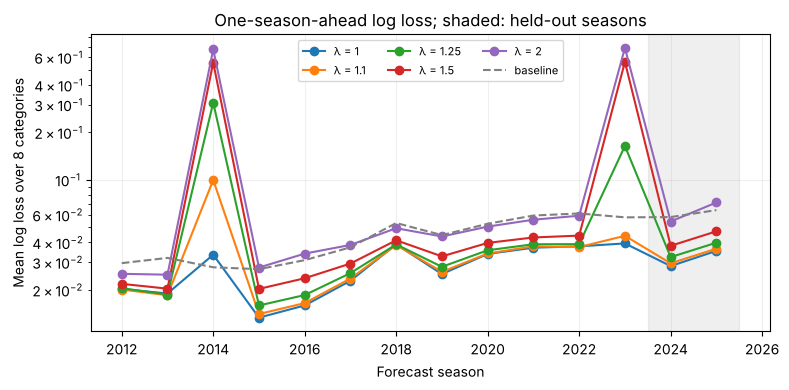

In [11]:
fig, ax = plt.subplots(figsize=(8, 4))
for lam in LAMBDAS:
    a = annual.loc[lam].log_loss
    ax.plot(a.index, a.values, marker="o", label=f"λ = {lam:g}")
base = scores[scores.model == "baseline"].groupby("season").log_loss.mean()
ax.plot(base.index, base.values, "--", color="gray", label="baseline")
ax.axvspan(TEST_SEASONS[0] - 0.5, TEST_SEASONS[-1] + 0.5, color="gray", alpha=0.12)
ax.set(xlabel="Forecast season", ylabel="Mean log loss over 8 categories", yscale="log",
       title="One-season-ahead log loss; shaded: held-out seasons")
ax.legend(ncol=3, fontsize=8); ax.grid(alpha=0.2)
fig.tight_layout(); fig.savefig(OUTPUT / "log_loss_by_season.png", dpi=160); plt.show()

**The two spikes.** The large losses in 2014 and 2023 come from ceremony indicators that change for everyone at once: iHeartRadio starts in
season 2014 (`iheart_held` switches from 0 to 1) and there is no AMA ceremony in season 2023 (`ama_held` switches from 1 to 0). Within one
season such an indicator is the same for all candidates, so the data identify it only through its contrast with earlier seasons. Forgetting
erases that contrast: the coefficient drifts with the intercept, and when the indicator flips, every candidate's probability jumps. The table
below drops those two seasons; $\lambda = 1$ is still best, so the conclusion does not rest on the spikes.

In [12]:
calm = scores[(scores.period == "tuning 2012-2023") & ~scores.season.isin([2014, 2023])]
calm.groupby("model")[["brier", "log_loss", "precision_at_5"]].mean().reindex(order).round(5)

,brier,log_loss,precision_at_5
model,,,
baseline,0.00711,0.04264,0.00716
lambda=1,0.00596,0.02635,0.39500
lambda=1.1,0.00602,0.02660,0.39250
lambda=1.25,0.00631,0.02791,0.39250
lambda=1.5,0.00724,0.03158,0.34500
lambda=2,0.00927,0.04079,0.30500


### How much past data each λ keeps

Inflating the covariance by $\lambda$ each year down-weights a season $k$ years old by roughly $\lambda^{-k}$. The effective number of past
seasons is $\sum_k \lambda^{-k} \approx \lambda/(\lambda-1)$ for long histories. Each category has only about five to ten nominated artists per
season, so a short memory leaves few positive examples for 28 coefficients.

In [13]:
memory = pd.DataFrame({"lambda": LAMBDAS,
                       "weight of season 5 years back": [l ** -5 for l in LAMBDAS],
                       "effective past seasons (over 26)": [sum(l ** -k for k in range(26)) for l in LAMBDAS]})
pos_per_season = data[data.season < FORECAST_SEASON].groupby(["cat", "season"]).nominated.sum().groupby("cat").mean()
memory["approx. nominated artists in memory, per category"] = memory["effective past seasons (over 26)"] * pos_per_season.mean()
memory.round(3)

,lambda,weight of season 5 years back,effective past seasons (over 26),"approx. nominated artists in memory, per category"
0,1.00,1.000,26.000,171.000
1,1.10,0.621,10.077,66.276
2,1.25,0.328,4.985,32.785
3,1.50,0.132,3.000,19.730
4,2.00,0.031,2.000,13.154


## 8. All Stage 1 models side by side

To place forgetting among the other Stage 1 variants, the same one-season-ahead backtest is run for:

* **non-Bayesian probit** (maximum likelihood, no prior) with only the eight Billboard chart predictors, and with all 27 predictors;
* **Bayesian probit with only the Billboard predictors** (same priors as the full model);
* **Bayesian probit, full** — the $\lambda=1$ run above, and the main report's NUTS fit (`exports_stage1`, held-out seasons only);
* **Bayesian probit with forgetting**, $\lambda > 1$.

The non-Bayesian and Billboard-only models are refitted on all earlier seasons for every forecast season. Maximum likelihood is computed as
the posterior mode under a nearly flat prior ($N(0, 10^6)$); its forecasts plug in the point estimate, $\Phi(z^\top \hat w)$, because it has no
posterior to average over. A predictor that is constant in the training seasons (iHeartRadio before 2014) then gets coefficient zero.

**Hits in the top five** count the nominated artists among the five highest-probability artists of each category-season: 16 events and
80 places in 2024–2025, 96 events and 480 places in 2012–2023. For the baseline, which ranks nobody, the expected number of hits of a random
list is shown.

In [14]:
BILLBOARD = [i for i, f in enumerate(FEATURE_NAMES) if f.startswith(("h_", "b_", "log_h_", "log_b_"))]
print("Billboard predictors:", [FEATURE_NAMES[i] for i in BILLBOARD])
FLAT = 1e6

refit = []
for cat in CATEGORIES:
    d, Z = design(cat)
    y = d.nominated.to_numpy().astype(float)
    for name, cols_, bayes in [("Non-Bayesian probit, Billboard", BILLBOARD, False),
                               ("Non-Bayesian probit, full", None, False),
                               ("Bayesian probit, Billboard", BILLBOARD, True)]:
        Zc = Z if cols_ is None else Z[:, [0] + [i + 1 for i in cols_]]
        k = Zc.shape[1]
        if bayes:
            m0, S0 = PRIOR_MEAN[:k], PRIOR_COV[:k, :k]
        else:
            m0, S0 = np.zeros(k), FLAT * np.eye(k)
        for season in range(FIRST_EVAL, FORECAST_SEASON):
            train, test = (d.season < season).to_numpy(), (d.season == season).to_numpy()
            m, S = laplace_update(Zc[train], y[train], m0, S0)
            p = predictive(Zc[test], m, S) if bayes else ndtr(Zc[test] @ m)
            refit.append(pd.DataFrame({"model": name, "season": season, "cat": cat,
                                       "artist_key": d.artist_key.to_numpy()[test], "nominated": y[test], "p": p}))
refit = pd.concat(refit, ignore_index=True)

seq = preds[preds.season < FORECAST_SEASON].copy()
seq["model"] = np.where(seq.lam == 1.0, "Bayesian probit, full (Laplace)", "Bayesian probit, full, forgetting λ=" + seq.lam.map("{:g}".format))
parts = [refit, seq[["model", "season", "cat", "artist_key", "nominated", "p"]]]
if nuts is not None:
    parts.append(nuts.assign(model="Bayesian probit, full (NUTS, main report)", p=nuts.p_probit)
                 .merge(data[["season", "cat", "artist_key", "nominated"]], on=["season", "cat", "artist_key"])
                 [["model", "season", "cat", "artist_key", "nominated", "p"]])
allp = pd.concat(parts, ignore_index=True)

def event_scores(block):
    top = block.sort_values(["p", "artist_key"], ascending=[False, True]).head(TOP_K)
    p = np.clip(block.p.to_numpy(), 1e-12, 1 - 1e-12); y = block.nominated.to_numpy()
    return pd.Series({"brier": np.mean((p - y) ** 2),
                      "log_loss": -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p)),
                      "hits": top.nominated.sum()})
ev = allp.groupby(["model", "season", "cat"]).apply(event_scores, include_groups=False).reset_index()
# baseline: training rate; expected hits of a random five-artist list
base_ev = scores[scores.model == "baseline"][["season", "cat", "brier", "log_loss"]].copy()
base_ev["hits"] = [TOP_K * data.loc[(data.season == s) & (data.cat == c), "nominated"].mean()
                   for s, c in zip(base_ev.season, base_ev.cat)]
ev = pd.concat([ev, base_ev.assign(model="Baseline (equal probability)")], ignore_index=True)

def table(seasons):
    e = ev[ev.season.isin(seasons)]
    t = e.groupby("model").agg(events=("hits", "size"), brier=("brier", "mean"), log_loss=("log_loss", "mean"), hits=("hits", "sum"))
    t = t[t.events == len(seasons) * len(CATEGORIES)]          # models with forecasts for every event
    places = len(seasons) * len(CATEGORIES) * TOP_K
    t["hits in top five"] = [f"{h:.1f}/{places} (expected)" if m.startswith("Baseline") else f"{h:.0f}/{places} — {100*h/places:.2f}%"
                             for m, h in zip(t.index, t.hits)]
    return t.sort_values("brier")[["brier", "log_loss", "hits in top five"]].round(6)

comparison_test = table(TEST_SEASONS)
comparison_tune = table(range(FIRST_EVAL, TUNE_END + 1))
comparison_test.to_csv(OUTPUT / "model_comparison_2024_2025.csv")
comparison_tune.to_csv(OUTPUT / "model_comparison_2012_2023.csv")
print("Held-out seasons 2024-2025"); display(comparison_test)

Billboard predictors: ['h_peak_strength', 'log_h_entries', 'log_h_weeks', 'log_h_top10_weeks', 'b_peak_strength', 'log_b_entries', 'log_b_weeks', 'log_b_top10_weeks']


Held-out seasons 2024-2025


,brier,log_loss,hits in top five
model,,,
"Non-Bayesian probit, full",0.007533,0.032532,47/80 — 58.75%
"Bayesian probit, full (NUTS, main report)",0.007557,0.031311,47/80 — 58.75%
"Bayesian probit, full (Laplace)",0.007617,0.031775,48/80 — 60.00%
"Bayesian probit, full, forgetting λ=1.1",0.007737,0.032926,43/80 — 53.75%
"Bayesian probit, full, forgetting λ=1.25",0.008338,0.035998,42/80 — 52.50%
"Bayesian probit, Billboard",0.009019,0.036340,24/80 — 30.00%
"Non-Bayesian probit, Billboard",0.009026,0.036345,24/80 — 30.00%
"Bayesian probit, full, forgetting λ=1.5",0.009996,0.042484,37/80 — 46.25%
Baseline (equal probability),0.010766,0.060956,0.9/80 (expected)


In [15]:
print("Seasons 2012-2023"); display(comparison_tune)

Seasons 2012-2023


,brier,log_loss,hits in top five
model,,,
"Bayesian probit, full (Laplace)",0.006067,0.028018,182/480 — 37.92%
"Non-Bayesian probit, full",0.006149,0.033282,171/480 — 35.62%
"Bayesian probit, Billboard",0.006426,0.030169,120/480 — 25.00%
"Non-Bayesian probit, Billboard",0.006426,0.030214,120/480 — 25.00%
"Bayesian probit, full, forgetting λ=1.1",0.006756,0.034120,181/480 — 37.71%
Baseline (equal probability),0.007123,0.042652,3.4/480 (expected)
"Bayesian probit, full, forgetting λ=1.25",0.013543,0.062583,179/480 — 37.29%
"Bayesian probit, full, forgetting λ=1.5",0.036442,0.119144,155/480 — 32.29%
"Bayesian probit, full, forgetting λ=2",0.048209,0.147147,136/480 — 28.33%


## 9. Forecast for the 2027 Grammys

Forecasts for season 2026 (69th Grammys, nominations on 16 November 2026) under the $\lambda$ chosen on 2012–2023. The probabilities are
artist-level and are not forced to sum to the number of slots, as in the main report.

In [16]:
forecast = preds[preds.season == FORECAST_SEASON].copy()
forecast.to_csv(OUTPUT / "forecast_2027_all_lambdas.csv", index=False)
chosen = forecast[forecast.lam == best_lam].sort_values(["cat", "p"], ascending=[True, False])
chosen["rank"] = chosen.groupby("cat").cumcount() + 1
top = chosen[chosen["rank"] <= TOP_K]
top.to_csv(OUTPUT / "forecast_2027_top5.csv", index=False)
top.pivot(index="rank", columns="cat", values="artist")

cat,album_of_the_year,best_new_artist,music_video,pop_duo_group,pop_solo,pop_vocal_album,record_of_the_year,song_of_the_year
rank,,,,,,,,
1,Taylor Swift,Sienna Spiro,Taylor Swift,Taylor Swift,Taylor Swift,Taylor Swift,Taylor Swift,Bruno Mars
2,Olivia Dean,Ella Langley,Sabrina Carpenter,BTS,Sabrina Carpenter,Sabrina Carpenter,Olivia Dean,Taylor Swift
3,Sabrina Carpenter,STELLA LEFTY,Madonna,Lady Gaga,Ariana Grande,Ariana Grande,Bruno Mars,Olivia Dean
4,Ariana Grande,Bella Kay,BTS,Ariana Grande,Bruno Mars,Olivia Rodrigo,Ella Langley,Sabrina Carpenter
5,BTS,Malcolm Todd,Ariana Grande,Bruno Mars,Lady Gaga,Lady Gaga,Sabrina Carpenter,Lady Gaga


In [17]:
# how the shortlist changes with forgetting: probability of the chosen-lambda top 5 under each lambda
wide = forecast.pivot_table(index=["cat", "artist"], columns="lam", values="p")
wide.loc[[(c, a) for c, a in zip(top.cat, top.artist)]].round(3)

lam                                    1.00   1.10   1.25   1.50   2.00
cat                artist                                              
album_of_the_year  Taylor Swift       0.655  0.706  0.738  0.753  0.764
                   Olivia Dean        0.543  0.572  0.573  0.541  0.475
                   Sabrina Carpenter  0.490  0.413  0.346  0.338  0.384
                   Ariana Grande      0.477  0.475  0.472  0.450  0.400
                   BTS                0.453  0.464  0.451  0.418  0.365
best_new_artist    Sienna Spiro       0.405  0.588  0.760  0.786  0.721
                   Ella Langley       0.306  0.251  0.206  0.219  0.320
                   STELLA LEFTY       0.254  0.330  0.453  0.531  0.553
                   Bella Kay          0.198  0.280  0.413  0.507  0.531
                   Malcolm Todd       0.195  0.203  0.249  0.295  0.319
music_video        Taylor Swift       0.759  0.781  0.675  0.459  0.488
                   Sabrina Carpenter  0.336  0.299  0.279  0.264  0.236
                   Madonna            0.277  0.258  0.194  0.154  0.173
                   BTS                0.228  0.286  0.284  0.242  0.224
                   Ariana Grande      0.168  0.221  0.263  0.278  0.313
pop_duo_group      Taylor Swift       0.552  0.385  0.264  0.222  0.248
                   BTS                0.480  0.475  0.507  0.554  0.565
                   Lady Gaga          0.454  0.354  0.301  0.272  0.306
                   Ariana Grande      0.452  0.388  0.343  0.294  0.247
                   Bruno Mars         0.313  0.300  0.306  0.293  0.299
pop_solo           Taylor Swift       0.719  0.645  0.610  0.615  0.637
                   Sabrina Carpenter  0.581  0.582  0.559  0.582  0.628
                   Ariana Grande      0.453  0.513  0.514  0.419  0.314
                   Bruno Mars         0.307  0.236  0.211  0.226  0.289
                   Lady Gaga          0.299  0.307  0.331  0.393  0.413
pop_vocal_album    Taylor Swift       0.745  0.609  0.484  0.488  0.499
                   Sabrina Carpenter  0.712  0.781  0.683  0.538  0.502
                   Ariana Grande      0.577  0.695  0.754  0.760  0.730
                   Olivia Rodrigo     0.446  0.561  0.633  0.635  0.579
                   Lady Gaga          0.308  0.229  0.184  0.206  0.251
record_of_the_year Taylor Swift       0.740  0.763  0.793  0.802  0.749
                   Olivia Dean        0.730  0.770  0.785  0.758  0.722
                   Bruno Mars         0.641  0.683  0.653  0.611  0.578
                   Ella Langley       0.536  0.602  0.655  0.690  0.721
                   Sabrina Carpenter  0.399  0.414  0.430  0.444  0.445
song_of_the_year   Bruno Mars         0.775  0.840  0.839  0.805  0.746
                   Taylor Swift       0.607  0.671  0.733  0.758  0.709
                   Olivia Dean        0.518  0.487  0.480  0.498  0.502
                   Sabrina Carpenter  0.508  0.481  0.472  0.494  0.510
                   Lady Gaga          0.461  0.544  0.562  0.538  0.458

## 10. Conclusions

In [18]:
t = summary.loc["test 2024-2025"]; u = summary.loc["tuning 2012-2023"]
print(f"Chosen lambda (tuning 2012-2023, log loss): {best_lam:g}")
for lam in LAMBDAS:
    k = f"lambda={lam:g}"
    print(f"{k:12s} tuning log loss {u.loc[k,'log_loss']:.4f} | test log loss {t.loc[k,'log_loss']:.4f}, "
          f"Brier {t.loc[k,'brier']:.5f}, precision@5 {t.loc[k,'precision_at_5']:.3f}")
print(f"baseline     test log loss {t.loc['baseline','log_loss']:.4f}, Brier {t.loc['baseline','brier']:.5f}")
if nuts is not None:
    print(f"main report NUTS probit, test Brier (same rows): "
          f"{np.mean(both.groupby(['season','cat']).apply(lambda b: np.mean((b.p_probit-b.nominated)**2), include_groups=False)):.5f}")

Chosen lambda (tuning 2012-2023, log loss): 1
lambda=1     tuning log loss 0.0280 | test log loss 0.0318, Brier 0.00762, precision@5 0.600
lambda=1.1   tuning log loss 0.0341 | test log loss 0.0329, Brier 0.00774, precision@5 0.537
lambda=1.25  tuning log loss 0.0626 | test log loss 0.0360, Brier 0.00834, precision@5 0.525
lambda=1.5   tuning log loss 0.1191 | test log loss 0.0425, Brier 0.01000, precision@5 0.463
lambda=2     tuning log loss 0.1472 | test log loss 0.0629, Brier 0.01344, precision@5 0.425
baseline     test log loss 0.0610, Brier 0.01077
main report NUTS probit, test Brier (same rows): 0.00756


**Interpretation.** Forecasts get worse as $\lambda$ grows, on the tuning seasons and on the held-out seasons alike, so the data give no
support for forgetting at the scale tried here: with five to ten nominations per category and season, discarding old seasons removes more
signal than any drift in the Academy's preferences adds. This agrees with Pardoe and Simonton, who found that down-weighting older Oscar years
and moving windows did not improve accuracy. Sequential updating with $\lambda = 1$ reproduces the all-data fit and the main report's NUTS forecasts,
so the main report's approach of refitting on all past seasons stands.

**Limitations.** Forgetting here inflates all coefficients equally, including the season-constant ceremony indicators, which caused the
2014 and 2023 spikes; excluding the indicators from forgetting, or forgetting only selected coefficients, would be a cleaner test; drift could affect only some (for example the baseline rate after the
2021 rule changes), which a coefficient-specific $\lambda$ could test. The Laplace approximation replaces NUTS within each update. The
evaluation uses one-season-ahead forecasts on a retrospectively assembled dataset, with the caveats of the main report.